In [1]:
from lights.load_data import *
from lights.plotting import categorical_cmap
from lights.constants import mB, mK, mKs
from lights.signal_rates import Nrec_BelleII, s_SM_BelleII, Nrec_BaBar, s_SM_BaBar

import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from joblib import Parallel, delayed
cmap = plt.get_cmap("tab10")

from lights.paths import PLOTS_DIR
SAVE_DIR = PLOTS_DIR / "coupling_fits"

# Use LaTeX (Computer Modern) if installed; otherwise fall back to mathtext's CM fonts.
# /Library/TeX/texbin is the MacTeX location, which GUI apps may not have on PATH.
if os.path.isdir("/Library/TeX/texbin"):
    os.environ["PATH"] += os.pathsep + "/Library/TeX/texbin"
plt.rcParams.update({
    "font.size": 20,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "mathtext.fontset": "cm",
    "text.usetex": shutil.which("latex") is not None,
})

In [2]:
from lights.branching_fractions import cdict
from lights.likelihoods import logLL_BelleII, min_logLL, profile_logLL_scan

mu_val, mu_err, m_BelleII, mu_min = min_logLL(logLL_BelleII, Nrec_BelleII)

# Two-body scenarios

In [3]:
Npts = [100, 100]

MX = 2.1
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CSL_s']] = 1e-8/2
CNP_1[cdict['CSR_s']] = 1e-8/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CSL_s']] = 1e-8/2
CNP_2[cdict['CSR_s']] = -1e-8/2
LAMBDA = 1.

LL_BelleII_gSgP, LL_BaBar_gSgP, LL_LEP_gSgP, LL_comb_gSgP = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                               [-8, 8], [-30, 30], 
                                                                               pts = Npts, 
                                                                               Lambda = LAMBDA, 
                                                                               sig = [1,1,1,1])

mX = 2.1: 100%|██████████| 10000/10000 [00:09<00:00, 1021.52it/s]


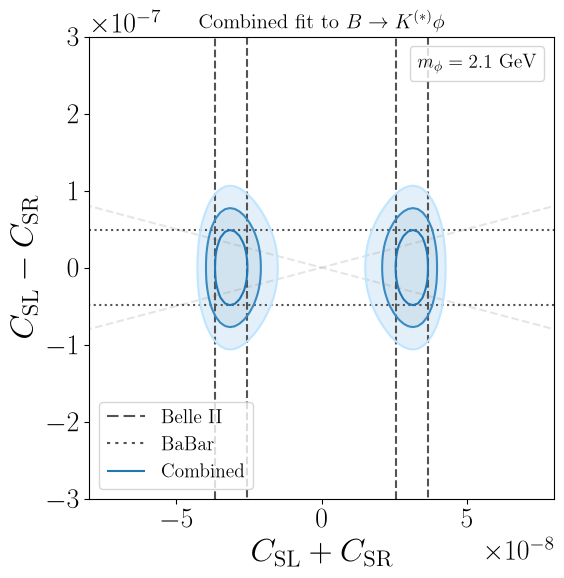

In [4]:
fig, axes = plt.subplots(nrows=1, ncols=1)

cmapt = categorical_cmap(0, 1, 6, cmap="tab10")

plt.plot([-2e-7, 2e-7], [2e-7, -2e-7], ls = '--', color = 'grey', alpha = 0.2)
plt.plot([-2e-7, 2e-7], [-2e-7, 2e-7], ls = '--', color = 'grey', alpha = 0.2)

c1_range = np.linspace(-8e-8, 8e-8, Npts[0])
c2_range = np.linspace(-30e-8, 30e-8, Npts[1])
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot1 = plt.contour(c1_range_f, c2_range_f, LL_BelleII_gSgP, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')
handles_1, labels_1 = tot1.legend_elements()

tot2 = plt.contour(c1_range_f, c2_range_f, LL_BaBar_gSgP, levels = [2.3], cmap = 'Greys', vmin = -20, vmax = 10, linestyles = ':')
handles_2, labels_2 = tot2.legend_elements()

tot3 = plt.contour(c1_range_f, c2_range_f, LL_comb_gSgP, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
plt.contourf(c1_range_f, c2_range_f, LL_comb_gSgP, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)
handles_3, labels_3 = tot3.legend_elements()

plt.ticklabel_format(style='sci', axis='both', scilimits=(0,0))

axes.set_xlim(-8e-8, 8e-8);
axes.set_ylim(-30e-8, 30e-8);

axes.set_xlabel(r'$C_{\rm SL} + C_{\rm SR}$', fontsize = 24);
axes.set_ylabel(r'$C_{\rm SL} - C_{\rm SR}$', fontsize = 24);

tot1 = plt.plot([9e-7,10e-7],[9e-7,10e-7], linewidth = 0)

leg1 = axes.legend(tot1, [r'$m_\phi = %1.1f$ GeV' % MX], loc='upper right',fontsize=14,frameon=True,handlelength=0, handletextpad=0)
leg2 = axes.legend((handles_1 + handles_2 + handles_3)[0:3], [r'Belle II', r'BaBar', r'Combined'], loc='lower left',fontsize=14,frameon=True)
axes.add_artist(leg1)

plt.title(r'Combined fit to $B\to K^{(*)} \phi$', fontsize = 15);

fig.set_size_inches(6, 6)
plt.savefig(SAVE_DIR / "2body_scalar_scalarcoupling.pdf", bbox_inches='tight')

In [5]:
Npts = [100, 100]

MX = 2.1
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_v']] = 1e-8/2
CNP_1[cdict['CVR_v']] = 1e-8/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVL_v']] = 1e-8/2
CNP_2[cdict['CVR_v']] = -1e-8/2
LAMBDA = 1.

LL_BelleII_hVhA, LL_BaBar_hVhA, LL_LEP_hVhA, LL_comb_hVhA = profile_logLL_scan(MX, CNP_1, CNP_2, [-3, 3], [-8, 8], pts = Npts, Lambda = LAMBDA, sig = [1,1,1,1])

mX = 2.1: 100%|██████████| 10000/10000 [00:05<00:00, 1995.58it/s]


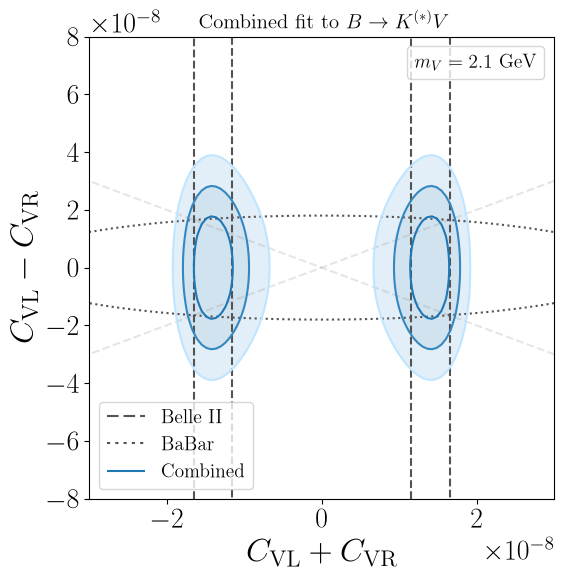

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=1)

cmapt = categorical_cmap(0, 1, 200, cmap="tab10")

plt.plot([-2e-7, 2e-7], [2e-7, -2e-7], ls = '--', color = 'grey', alpha = 0.2)
plt.plot([-2e-7, 2e-7], [-2e-7, 2e-7], ls = '--', color = 'grey', alpha = 0.2)

c1_range = np.linspace(-3e-8, 3e-8, Npts[0])
c2_range = np.linspace(-8e-8, 8e-8, Npts[1])
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot1 = plt.contour(c1_range_f, c2_range_f, LL_BelleII_hVhA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')
handles_1, labels_1 = tot1.legend_elements()

tot2 = plt.contour(c1_range_f, c2_range_f, LL_BaBar_hVhA, levels = [2.3], cmap = 'Greys', vmin = -20, vmax = 10, linestyles = ':')
handles_2, labels_2 = tot2.legend_elements()

tot3 = plt.contour(c1_range_f, c2_range_f, LL_comb_hVhA, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
plt.contourf(c1_range_f, c2_range_f, LL_comb_hVhA, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)
handles_3, labels_3 = tot3.legend_elements()

plt.ticklabel_format(style='sci', axis='both', scilimits=(0,0))

axes.set_xlim(-3e-8, 3e-8);
axes.set_ylim(-8e-8, 8e-8);

axes.set_xlabel(r'$C_{\rm VL} + C_{\rm VR}$', fontsize = 24);
axes.set_ylabel(r'$C_{\rm VL} - C_{\rm VR}$', fontsize = 24);

tot1 = plt.plot([9e-7,10e-7],[9e-7,10e-7], linewidth = 0)

leg1 = axes.legend(tot1, [r'$m_V = %1.1f$ GeV' % MX], loc='upper right',fontsize=14,frameon=True,handlelength=0, handletextpad=0)
leg2 = axes.legend((handles_1 + handles_2 + handles_3)[0:3], [r'Belle II', r'BaBar', r'Combined'], loc='lower left',fontsize=14,frameon=True)
axes.add_artist(leg1)

plt.title(r'Combined fit to $B\to K^{(*)} V$', fontsize = 15);

fig.set_size_inches(6, 6)
plt.savefig(SAVE_DIR / "2body_vector_vectorcoupling.pdf", bbox_inches='tight')

In [7]:
Npts = [100, 100]

MX = 2.1
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CTL_v']] = 1e-4/2
CNP_1[cdict['CTR_v']] = 1e-4/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CTL_v']] = 1e-4/2
CNP_2[cdict['CTR_v']] = -1e-4/2
LAMBDA = 1e4

LL_BelleII_hThTt, LL_BaBar_hThTt, LL_LEP_hThTt, LL_comb_hThTt = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                   [-2, 2], [-2, 2], 
                                                                                   pts = Npts, 
                                                                                   Lambda = LAMBDA, 
                                                                                   sig = [1,1,1,1])

mX = 2.1: 100%|██████████| 10000/10000 [00:04<00:00, 2170.14it/s]


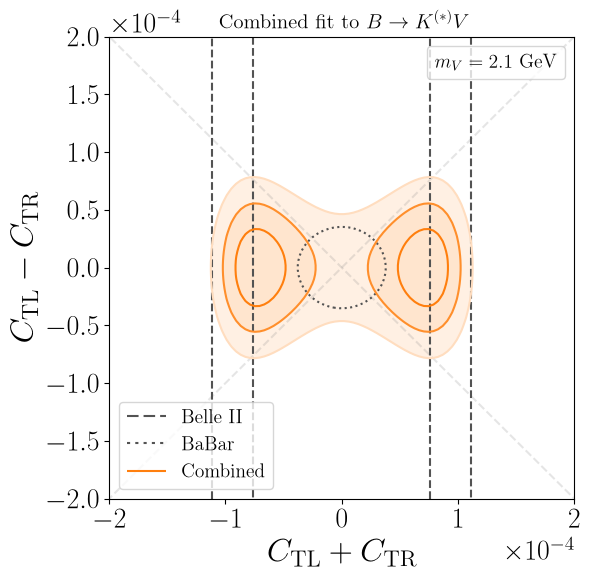

In [8]:
fig, axes = plt.subplots(nrows=1, ncols=1)

cmapt = categorical_cmap(1, 2, 200, cmap="tab10")

plt.plot([-5e-4, 5e-4], [5e-4, -5e-4], ls = '--', color = 'grey', alpha = 0.2)
plt.plot([-5e-4, 5e-4], [-5e-4, 5e-4], ls = '--', color = 'grey', alpha = 0.2)

c1_range = np.linspace(-2e-4, 2e-4, Npts[0])
c2_range = np.linspace(-2e-4, 2e-4, Npts[1])
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot1 = plt.contour(c1_range_f, c2_range_f, LL_BelleII_hThTt, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')
handles_1, labels_1 = tot1.legend_elements()

tot2 = plt.contour(c1_range_f, c2_range_f, LL_BaBar_hThTt, levels = [2.3], cmap = 'Greys', vmin = -20, vmax = 10, linestyles = ':')
handles_2, labels_2 = tot2.legend_elements()

tot3 = plt.contour(c1_range_f, c2_range_f, LL_comb_hThTt, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
plt.contourf(c1_range_f, c2_range_f, LL_comb_hThTt, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)
handles_3, labels_3 = tot3.legend_elements()

plt.ticklabel_format(style='sci', axis='both', scilimits=(0,0))

axes.set_xlim(-2e-4, 2e-4);
axes.set_ylim(-2e-4, 2e-4);

axes.set_xlabel(r'$C_{\rm TL} + C_{\rm TR}$', fontsize = 24);
axes.set_ylabel(r'$C_{\rm TL} - C_{\rm TR}$', fontsize = 24);

tot1 = plt.plot([9e-7,10e-7],[9e-7,10e-7], linewidth = 0)

leg1 = axes.legend(tot1, [r'$m_V = %1.1f$ GeV' % MX], loc='upper right',fontsize=14,frameon=True,handlelength=0, handletextpad=0)
leg2 = axes.legend((handles_1 + handles_2 + handles_3)[0:3], [r'Belle II', r'BaBar', r'Combined'], loc='lower left',fontsize=14,frameon=True)
axes.add_artist(leg1)

plt.title(r'Combined fit to $B\to K^{(*)} V$', fontsize = 15);

fig.set_size_inches(6, 6)
plt.savefig(SAVE_DIR / "2body_vector_tensorcoupling.pdf", bbox_inches='tight')

# Three-body scenarios

In [9]:
Npts = [100, 100]

MX = 0.52
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CSL_ss']] = 1e-3/2
CNP_1[cdict['CSR_ss']] = 1e-3/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CSL_ss']] = 1e-3/2
CNP_2[cdict['CSR_ss']] = -1e-3/2
LAMBDA = 1e4

LL_BelleII_gSSgPS, LL_BaBar_gSSgPS, LL_LEP_gSSgPS, LL_comb_gSSgPS = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-6, 6], [-10, 10], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, 
                                                                                       sig = [1,1,1,1])

mX = 0.52: 100%|██████████| 10000/10000 [00:04<00:00, 2110.46it/s]


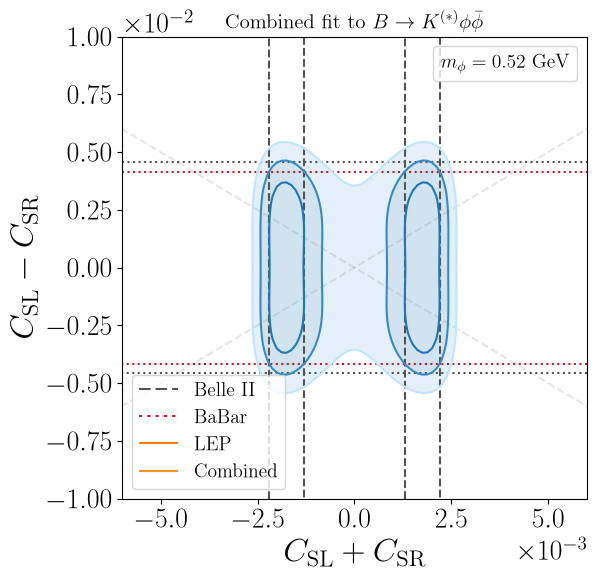

In [11]:
fig, axes = plt.subplots(nrows=1, ncols=1)

cmapt = categorical_cmap(0, 1, 6, cmap="tab10")

plt.plot([-7e-3, 7e-3], [7e-3, -7e-3], ls = '--', color = 'grey', alpha = 0.2)
plt.plot([-7e-3, 7e-3], [-7e-3, 7e-3], ls = '--', color = 'grey', alpha = 0.2)

c1_range = np.linspace(-6e-3, 6e-3, Npts[0])
c2_range = np.linspace(-10e-3, 10e-3, Npts[1])
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot1 = plt.contour(c1_range_f, c2_range_f, LL_BelleII_gSSgPS, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')
handles_1, labels_1 = tot1.legend_elements()

tot2 = plt.contour(c1_range_f, c2_range_f, LL_BaBar_gSSgPS, levels = [2.3], cmap = 'Greys', vmin = -20, vmax = 10, linestyles = ':')
handles_2, labels_2 = tot2.legend_elements()

tot3 = plt.contour(c1_range_f, c2_range_f, LL_LEP_gSSgPS, levels = [2.3], cmap = 'Reds', vmin = -20, vmax = 10, linestyles = ':')
handles_2, labels_2 = tot3.legend_elements()

tot4 = plt.contour(c1_range_f, c2_range_f, LL_comb_gSSgPS, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
plt.contourf(c1_range_f, c2_range_f, LL_comb_gSSgPS, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)
handles_4, labels_4 = tot3.legend_elements()

plt.ticklabel_format(style='sci', axis='both', scilimits=(0,0))

axes.set_xlim(-6e-3, 6e-3);
axes.set_ylim(-10e-3, 10e-3);

axes.set_xlabel(r'$C_{\rm SL} + C_{\rm SR}$', fontsize = 24);
axes.set_ylabel(r'$C_{\rm SL} - C_{\rm SR}$', fontsize = 24);

tot1 = plt.plot([9e-7,10e-7],[9e-7,10e-7], linewidth = 0)

leg1 = axes.legend(tot1, [r'$m_\phi = %1.2f$ GeV' % MX], loc='upper right',fontsize=14,frameon=True,handlelength=0, handletextpad=0)
leg2 = axes.legend((handles_1 + handles_2 + handles_3 + handles_4)[0:4], [r'Belle II', r'BaBar', r'LEP', r'Combined'], 
                   loc='lower left',fontsize=14,frameon=True)
axes.add_artist(leg1)

plt.title(r'Combined fit to $B\to K^{(*)} \phi \bar{\phi}$', fontsize = 15);

fig.set_size_inches(6, 6)
plt.savefig(SAVE_DIR / "3body_scalar_scalarcoupling.pdf", bbox_inches='tight')

In [12]:
Npts = [100, 100]

MX = 0.38
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ss']] = 1/2
CNP_1[cdict['CVR_ss']] = 1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVL_ss']] = 1/2
CNP_2[cdict['CVR_ss']] = -1/2
LAMBDA = 1e4

LL_BelleII_gVVgAV, LL_BaBar_gVVgAV, LL_LEP_gVVgAV, LL_comb_gVVgAV = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-20, 20], [-40, 40], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, sig = [1,1,1,1])

mX = 0.38: 100%|██████████| 10000/10000 [00:04<00:00, 2373.91it/s]


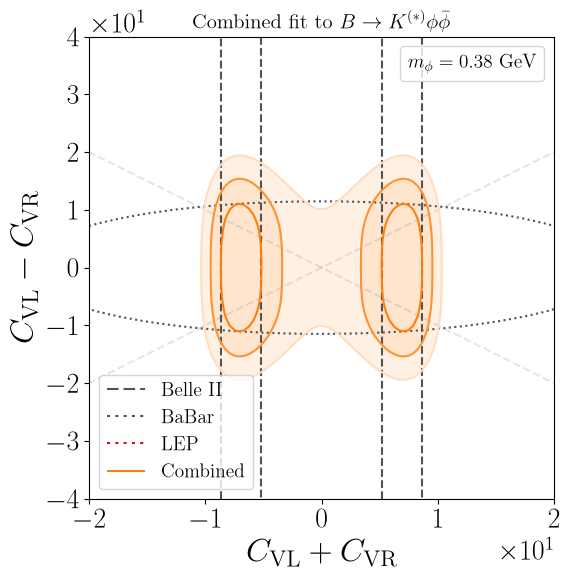

In [13]:
fig, axes = plt.subplots(nrows=1, ncols=1)

cmapt = categorical_cmap(1, 2, 6, cmap="tab10")

plt.plot([-50, 50], [50, -50], ls = '--', color = 'grey', alpha = 0.2)
plt.plot([-50, 50], [-50, 50], ls = '--', color = 'grey', alpha = 0.2)

c1_range = np.linspace(-20, 20, Npts[0])
c2_range = np.linspace(-40, 40, Npts[1])
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot1 = plt.contour(c1_range_f, c2_range_f, LL_BelleII_gVVgAV, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')
handles_1, labels_1 = tot1.legend_elements()

tot2 = plt.contour(c1_range_f, c2_range_f, LL_BaBar_gVVgAV, levels = [2.3], cmap = 'Greys', vmin = -20, vmax = 10, linestyles = ':')
handles_2, labels_2 = tot2.legend_elements()

tot3 = plt.contour(c1_range_f, c2_range_f, LL_LEP_gVVgAV, levels = [2.3], cmap = 'Reds', vmin = -20, vmax = 10, linestyles = ':')
handles_3, labels_3 = tot3.legend_elements()

tot4 = plt.contour(c1_range_f, c2_range_f, LL_comb_gVVgAV, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
plt.contourf(c1_range_f, c2_range_f, LL_comb_gVVgAV, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)
handles_4, labels_4 = tot4.legend_elements()

plt.ticklabel_format(style='sci', axis='both', scilimits=(0,0))

axes.set_xlim(-20, 20);
axes.set_ylim(-40, 40);

axes.set_xlabel(r'$C_{\rm VL} + C_{\rm VR}$', fontsize = 24);
axes.set_ylabel(r'$C_{\rm VL} - C_{\rm VR}$', fontsize = 24);

tot1 = plt.plot([9e-7,10e-7],[9e-7,10e-7], linewidth = 0)

leg1 = axes.legend(tot1, [r'$m_\phi = %1.2f$ GeV' % MX], loc='upper right',fontsize=14,frameon=True,handlelength=0, handletextpad=0)
leg2 = axes.legend((handles_1 + handles_2 + handles_3 + handles_4)[0:4], [r'Belle II', r'BaBar', r'LEP', r'Combined'], loc='lower left',fontsize=14,frameon=True)
axes.add_artist(leg1)

plt.title(r'Combined fit to $B\to K^{(*)} \phi \bar{\phi}$', fontsize = 15);

fig.set_size_inches(6, 6)
plt.savefig(SAVE_DIR / "3body_scalar_vectorcoupling.pdf", bbox_inches='tight')

In [14]:
# fVV - fVA
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1/2
CNP_1[cdict['CVR_ff']] = 1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVLp_ff']] = 1/2
CNP_2[cdict['CVRp_ff']] = 1/2
LAMBDA = 1e4

LL_BelleII_fVVfVA, LL_BaBar_fVVfVA, LL_LEP_fVVfVA, LL_comb_fVVfVA = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-6, 6], [-6, 6], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, 
                                                                                       sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2307.28it/s]


In [15]:
# fVV - fAV
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1/2
CNP_1[cdict['CVR_ff']] = 1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVL_ff']] = 1/2
CNP_2[cdict['CVR_ff']] = -1/2
LAMBDA = 1e4

LL_BelleII_fVVfAV, LL_BaBar_fVVfAV, LL_LEP_fVVfAV, LL_comb_fVVfAV = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-6, 6], [-12, 12], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, 
                                                                                       sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2390.92it/s]


In [16]:
# fVV - fAA
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1/2
CNP_1[cdict['CVR_ff']] = 1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVLp_ff']] = 1/2
CNP_2[cdict['CVRp_ff']] = -1/2
LAMBDA = 1e4

LL_BelleII_fVVfAA, LL_BaBar_fVVfAA, LL_LEP_fVVfAA, LL_comb_fVVfAA = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-6, 6], [-12, 12], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, 
                                                                                       sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2299.61it/s]


In [17]:
# fAV - fVA
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1/2
CNP_1[cdict['CVR_ff']] = -1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVLp_ff']] = 1/2
CNP_2[cdict['CVRp_ff']] = 1/2
LAMBDA = 1e4

LL_BelleII_fAVfVA, LL_BaBar_fAVfVA, LL_LEP_fAVfVA, LL_comb_fAVfVA = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-12, 12], [-6, 6], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, 
                                                                                       sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2237.57it/s]


In [18]:
# fAV - fAA
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1/2
CNP_1[cdict['CVR_ff']] = -1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVLp_ff']] = 1/2
CNP_2[cdict['CVRp_ff']] = -1/2
LAMBDA = 1e4

LL_BelleII_fAVfAA, LL_BaBar_fAVfAA, LL_LEP_fAVfAA, LL_comb_fAVfAA = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-12, 12], [-12, 12], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, 
                                                                                       sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2164.74it/s]


In [19]:
# fAA - fVA
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVLp_ff']] = 1/2
CNP_1[cdict['CVRp_ff']] = -1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVLp_ff']] = 1/2
CNP_2[cdict['CVRp_ff']] = 1/2
LAMBDA = 1e4

LL_BelleII_fAAfVA, LL_BaBar_fAAfVA, LL_LEP_fAAfVA, LL_comb_fAAfVA = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-12, 12], [-6, 6], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, 
                                                                                       sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2138.86it/s]


In [20]:
# fVV - fVA Majorana
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1/2
CNP_1[cdict['CVR_ff']] = 1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVLp_ff']] = 1/2
CNP_2[cdict['CVRp_ff']] = 1/2
LAMBDA = 1e4

LL_BelleII_fVVfVA_M, LL_BaBar_fVVfVA_M, LL_LEP_fVVfVA_M, LL_comb_fVVfVA_M = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                               [-6, 6], [-6, 6], 
                                                                                               pts = Npts, 
                                                                                               Lambda = LAMBDA, is_ident = True, 
                                                                                               sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2149.28it/s]


In [21]:
# fVV - fAV Majorana
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1/2
CNP_1[cdict['CVR_ff']] = 1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVL_ff']] = 1/2
CNP_2[cdict['CVR_ff']] = -1/2
LAMBDA = 1e4

LL_BelleII_fVVfAV_M, LL_BaBar_fVVfAV_M, LL_LEP_fVVfAV_M, LL_comb_fVVfAV_M = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                               [-6, 6], [-12, 12], 
                                                                                               pts = Npts, 
                                                                                               Lambda = LAMBDA, is_ident = True, 
                                                                                               sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2107.06it/s]


In [22]:
# fVV - fAA Majorana
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1/2
CNP_1[cdict['CVR_ff']] = 1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVLp_ff']] = 1/2
CNP_2[cdict['CVRp_ff']] = -1/2
LAMBDA = 1e4

LL_BelleII_fVVfAA_M, LL_BaBar_fVVfAA_M, LL_LEP_fVVfAA_M, LL_comb_fVVfAA_M = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-6, 6], [-12, 12], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, is_ident = True, 
                                                                                       sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2081.18it/s]


In [23]:
# fAV - fVA Majorana
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1/2
CNP_1[cdict['CVR_ff']] = -1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVLp_ff']] = 1/2
CNP_2[cdict['CVRp_ff']] = 1/2
LAMBDA = 1e4

LL_BelleII_fAVfVA_M, LL_BaBar_fAVfVA_M, LL_LEP_fAVfVA_M, LL_comb_fAVfVA_M = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-12, 12], [-6, 6], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, is_ident = True, 
                                                                                       sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2033.61it/s]


In [24]:
# fAV - fAA Majorana
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1/2
CNP_1[cdict['CVR_ff']] = -1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVLp_ff']] = 1/2
CNP_2[cdict['CVRp_ff']] = -1/2
LAMBDA = 1e4

LL_BelleII_fAVfAA_M, LL_BaBar_fAVfAA_M, LL_LEP_fAVfAA_M, LL_comb_fAVfAA_M = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-12, 12], [-12, 12], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, is_ident = True, 
                                                                                       sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2029.87it/s]


In [25]:
# fAA - fVA Majorana
Npts = [100, 100]

MX = 0.6
CNP_1 = np.zeros((6, 14))
CNP_1[cdict['CVLp_ff']] = 1/2
CNP_1[cdict['CVRp_ff']] = -1/2
CNP_2 = np.zeros((6, 14))
CNP_2[cdict['CVLp_ff']] = 1/2
CNP_2[cdict['CVRp_ff']] = 1/2
LAMBDA = 1e4

LL_BelleII_fAAfVA_M, LL_BaBar_fAAfVA_M, LL_LEP_fAAfVA_M, LL_comb_fAAfVA_M = profile_logLL_scan(MX, CNP_1, CNP_2, 
                                                                                       [-12, 12], [-6, 6], 
                                                                                       pts = Npts, 
                                                                                       Lambda = LAMBDA, is_ident = True, 
                                                                                       sig = [1,1,1,1])

mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2001.88it/s]


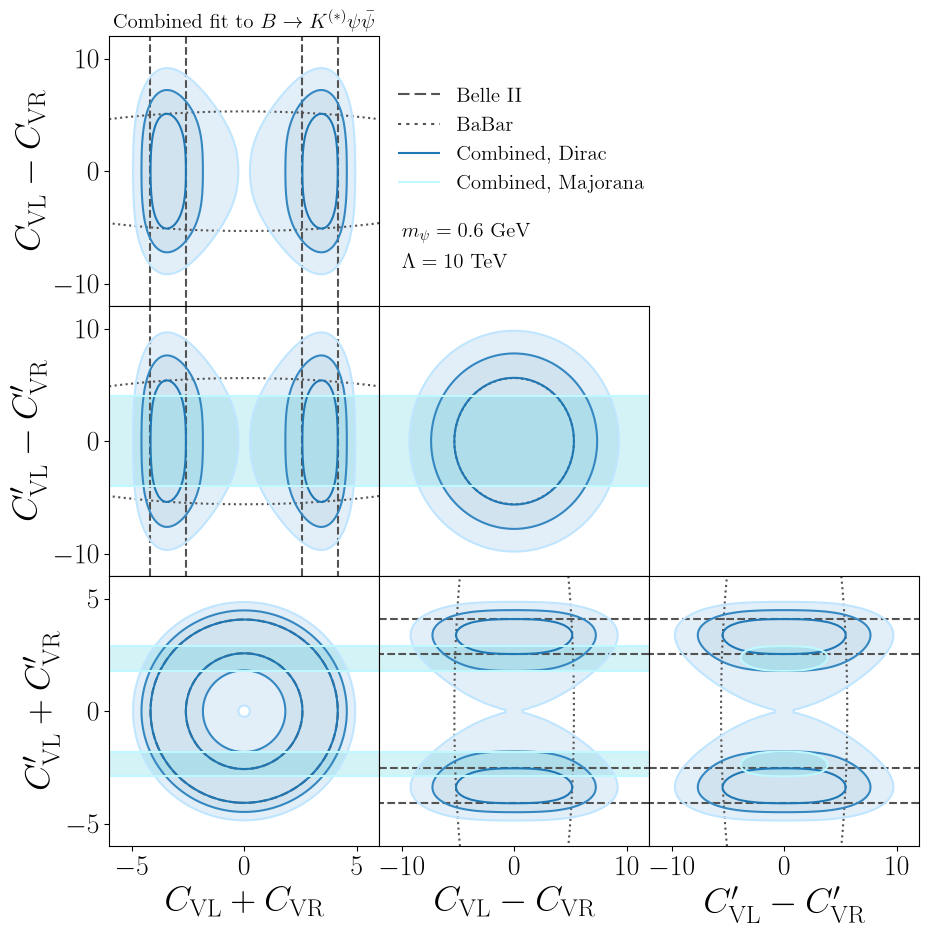

In [26]:
fig = plt.figure(figsize=(9,9))

cmapt = categorical_cmap(0, 1, 200, cmap="tab10")
cmapt2 = categorical_cmap(9, 10, 200, cmap="tab10")

Npts = 100

### fVV-fAV plot ###
ax1 = fig.add_axes([0., 0., 0.3, 0.3])

c1_range = np.linspace(-6, 6, Npts)
c2_range = np.linspace(-12, 12, Npts)
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
ax1.contour(c1_range_f, c2_range_f, LL_BelleII_fVVfAV, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
ax1.contour(c1_range_f, c2_range_f, LL_BaBar_fVVfAV, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = ':')

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot3 = ax1.contour(c1_range_f, c2_range_f, LL_comb_fVVfAV, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
ax1.contourf(c1_range_f, c2_range_f, LL_comb_fVVfAV, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)

# ax1.contour(c1_range_f, c2_range_f, LL_comb_fVVfAV_M, levels = [2.3], cmap = cmapt2, vmin = 1)
# ax1.contourf(c1_range_f, c2_range_f, LL_comb_fVVfAV_M, levels = [0,2.3], cmap = cmapt2, vmin = 1, alpha=0.2)

ax1.set_xticks([])
ax1.xaxis.set_ticklabels([], fontsize = 24)
ax1.set_xlim(-6,6)
ax1.set_ylim(-12,12)
ax1.set_ylabel(r'$C_{\rm VL} - C_{\rm VR}$', fontsize = 26);

plt.title(r'Combined fit to $B\to K^{(*)} \psi \bar{\psi}$', fontsize = 15);

### fVV-fAA plot ###
ax2 = fig.add_axes([0, -0.3, 0.3, 0.3])

c1_range = np.linspace(-6, 6, Npts)
c2_range = np.linspace(-12, 12, Npts)
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
ax2.contour(c1_range_f, c2_range_f, LL_BelleII_fVVfAA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
ax2.contour(c1_range_f, c2_range_f, LL_BaBar_fVVfAA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = ':')

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot3 = ax2.contour(c1_range_f, c2_range_f, LL_comb_fVVfAA, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
ax2.contourf(c1_range_f, c2_range_f, LL_comb_fVVfAA, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)

ax2.contour(c1_range_f, c2_range_f, LL_comb_fVVfAA_M, levels = [2.3], cmap = cmapt2, vmin = 1)
ax2.contourf(c1_range_f, c2_range_f, LL_comb_fVVfAA_M, levels = [0,2.3], cmap = cmapt2, vmin = 1, alpha=0.2)

ax2.set_xticks([])
ax2.xaxis.set_ticklabels([], fontsize = 24)
ax2.set_xlim(-6, 6)
ax2.set_ylim(-12, 12)
ax2.set_ylabel(r'$C_{\rm VL}^\prime - C_{\rm VR}^\prime$', fontsize = 26);

### fVV-fVA plot ###
ax3 = fig.add_axes([0, -0.6, 0.3, 0.3])

c1_range = np.linspace(-6, 6, Npts)
c2_range = np.linspace(-6, 6, Npts)
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
ax3.contour(c1_range_f, c2_range_f, LL_BelleII_fVVfVA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
ax3.contour(c1_range_f, c2_range_f, LL_BaBar_fVVfVA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = ':')

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot3 = ax3.contour(c1_range_f, c2_range_f, LL_comb_fVVfVA, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
ax3.contourf(c1_range_f, c2_range_f, LL_comb_fVVfVA, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)

ax3.contour(c1_range_f, c2_range_f, LL_comb_fVVfVA_M, levels = [2.3], cmap = cmapt2, vmin = 1)
ax3.contourf(c1_range_f, c2_range_f, LL_comb_fVVfVA_M, levels = [0,2.3], cmap = cmapt2, vmin = 1, alpha=0.2)

ax3.set_xlim(-6, 6)
ax3.set_ylim(-6, 6)
ax3.set_xlabel(r'$C_{\rm VL} + C_{\rm VR}$', fontsize = 26);
ax3.set_ylabel(r'$C_{\rm VL}^\prime + C_{\rm VR}^\prime$', fontsize = 26);

### fAV-fAA plot ###
ax4 = fig.add_axes([0.3, -0.3, 0.3, 0.3])

c1_range = np.linspace(-12, 12, Npts)
c2_range = np.linspace(-12, 12, Npts)
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
ax4.contour(c1_range_f, c2_range_f, LL_BelleII_fAVfAA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
ax4.contour(c1_range_f, c2_range_f, LL_BaBar_fAVfAA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = ':')

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot3 = ax4.contour(c1_range_f, c2_range_f, LL_comb_fAVfAA, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
ax4.contourf(c1_range_f, c2_range_f, LL_comb_fAVfAA, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)

ax4.contour(c1_range_f, c2_range_f, LL_comb_fAVfAA_M, levels = [2.3], cmap = cmapt2, vmin = 1)
ax4.contourf(c1_range_f, c2_range_f, LL_comb_fAVfAA_M, levels = [0,2.3], cmap = cmapt2, vmin = 1, alpha=0.2)

ax4.set_xlim(-12, 12)
ax4.set_ylim(-12, 12)
ax4.set_yticks([])
ax4.yaxis.set_ticklabels([], fontsize = 24)

### fAV-fVA plot ###
ax5 = fig.add_axes([0.3, -0.6, 0.3, 0.3])

c1_range = np.linspace(-12, 12, Npts)
c2_range = np.linspace(-6, 6, Npts)
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
ax5.contour(c1_range_f, c2_range_f, LL_BelleII_fAVfVA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
ax5.contour(c1_range_f, c2_range_f, LL_BaBar_fAVfVA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = ':')

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot3 = ax5.contour(c1_range_f, c2_range_f, LL_comb_fAVfVA, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
ax5.contourf(c1_range_f, c2_range_f, LL_comb_fAVfVA, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)

ax5.contour(c1_range_f, c2_range_f, LL_comb_fAVfVA_M, levels = [2.3], cmap = cmapt2, vmin = 1)
ax5.contourf(c1_range_f, c2_range_f, LL_comb_fAVfVA_M, levels = [0,2.3], cmap = cmapt2, vmin = 1, alpha=0.2)

ax5.set_xlim(-12, 12)
ax5.set_ylim(-6, 6)
ax5.set_yticks([])
ax5.yaxis.set_ticklabels([], fontsize = 24)
ax5.set_xlabel(r'$C_{\rm VL} - C_{\rm VR}$', fontsize = 26);

### fVA-fAA plot ###
ax6 = fig.add_axes([0.6, -0.6, 0.3, 0.3])

c1_range = np.linspace(-12, 12, Npts)
c2_range = np.linspace(-6, 6, Npts)
c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot1 = ax6.contour(c1_range_f, c2_range_f, LL_BelleII_fAAfVA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = '--')
handles_1, labels_1 = tot1.legend_elements()

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot2 = ax6.contour(c1_range_f, c2_range_f, LL_BaBar_fAAfVA, levels = [2.3], cmap ='Greys', vmin = -20, vmax = 10, linestyles = ':')
handles_2, labels_2 = tot2.legend_elements()

c1_range_f, c2_range_f = np.meshgrid(c1_range, c2_range)
tot3 = ax6.contour(c1_range_f, c2_range_f, LL_comb_fAAfVA, levels = [2.3, 6.18, 11.83], cmap = cmapt, vmin = 5)
ax6.contourf(c1_range_f, c2_range_f, LL_comb_fAAfVA, levels = [0, 2.3, 6.18, 11.83], cmap = cmapt, vmin = 5, alpha=0.2)
handles_3, labels_3 = tot3.legend_elements()

tot4 = ax6.contour(c1_range_f, c2_range_f, LL_comb_fAAfVA_M, levels = [2.3], cmap = cmapt2, vmin = 1)
ax6.contourf(c1_range_f, c2_range_f, LL_comb_fAAfVA_M, levels = [0,2.3], cmap = cmapt2, vmin = 1, alpha=0.2)
handles_4, labels_4 = tot4.legend_elements()

ax6.set_xlim(-12, 12)
ax6.set_ylim(-6, 6)
ax6.set_yticks([])
ax6.yaxis.set_ticklabels([], fontsize = 24)
ax6.set_xlabel(r'$C_{\rm VL}^\prime - C_{\rm VR}^\prime$', fontsize = 26);

# Legends

tot1, = ax3.plot([19,20],[19,20], linewidth = 0)
tot2, = ax3.plot([19,20],[19,20], linewidth = 0)
leg1 = ax3.legend([tot1, tot2], [r'$m_\psi = 0.6$ GeV',r'$\Lambda = 10$ TeV'], loc='upper right',fontsize=15,frameon=False,handlelength=0, handletextpad=0,bbox_to_anchor=(1.63, 2.38))
leg2 = ax3.legend(handles_1 + handles_2 + [handles_3[0]] + [handles_4[0]], [r'Belle II', r'BaBar', r'Combined, Dirac', r'Combined, Majorana'], loc='lower left',fontsize=15,frameon=False,bbox_to_anchor=(1.0, 2.35))

ax3.add_artist(leg1)

plt.savefig(SAVE_DIR / "3body_fermion_vectorcoupling.pdf", bbox_inches='tight')